# DP6 – Feature generation to make linear regression more powerful

**Data:** `dataFeatureGenerationForLinReg.csv` – columns `x1`, `x2` (inputs) and `y` (target), 200 rows.

**Idea:** A linear regression can only fit straight lines/planes: `y = b0 + b1·x1 + b2·x2`.
If the true relationship is curved, we can **generate new features** such as `x1²`, `x2²`, `x1·x2`.
The model is still *linear in its coefficients*, so we can still use linear regression – but now it can fit curves.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("../dataFeatureGenerationForLinReg.csv", sep="\t", header=None, names=["x1", "x2", "y"])
print(df.head())
X = df[["x1", "x2"]]
y = df["y"]

       x1      x2         y
0  1.8372  1.3119   7.08350
1 -3.6792 -1.4493  -0.80871
2  2.2272  4.9700  27.18600
3 -3.8965 -2.7583   5.57350
4 -3.8251  1.5245  -3.85050


## (a) Purely linear model
To **assess the fit graphically** we use two plots:
- **predicted vs. true**: points should lie on the diagonal
- **residuals** (true − predicted) vs. predicted: should be random noise around 0, **no pattern**

Model: y = 11.32 + 2.15*x1 + -0.82*x2
R²  : 0.421
MAE : 6.379


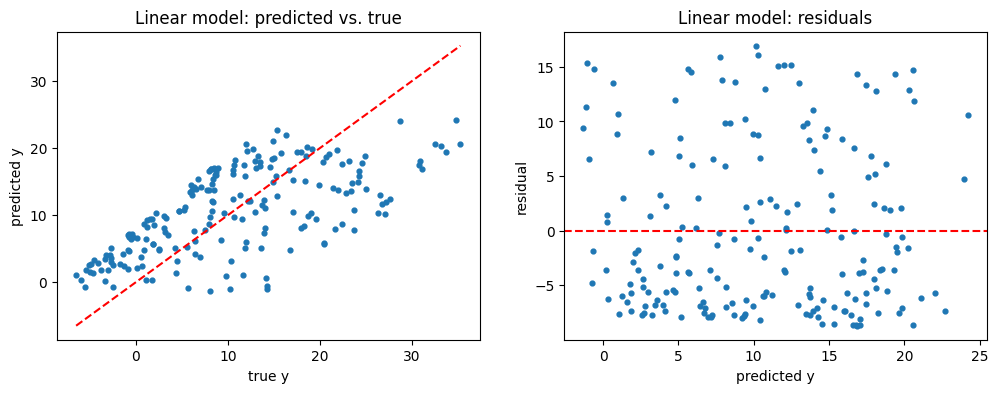

In [2]:
lin = LinearRegression().fit(X, y)
y_pred_lin = lin.predict(X)
print("Model: y = {:.2f} + {:.2f}*x1 + {:.2f}*x2".format(lin.intercept_, *lin.coef_))
print("R²  :", round(r2_score(y, y_pred_lin), 3))
print("MAE :", round(mean_absolute_error(y, y_pred_lin), 3))

def plot_fit(y_true, y_pred, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(y_true, y_pred, s=12)
    ax[0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
    ax[0].set_xlabel("true y"); ax[0].set_ylabel("predicted y"); ax[0].set_title(title + ": predicted vs. true")
    ax[1].scatter(y_pred, y_true - y_pred, s=12)
    ax[1].axhline(0, color="r", linestyle="--")
    ax[1].set_xlabel("predicted y"); ax[1].set_ylabel("residual"); ax[1].set_title(title + ": residuals")
    plt.show()

plot_fit(y, y_pred_lin, "Linear model")

➡ R² is only ≈ 0.42. The points do **not** follow the diagonal and the residuals show a clear **pattern** (not random noise).
→ The linear model is missing a non-linear part.

Let's look at y vs. each input to see where the curve comes from:

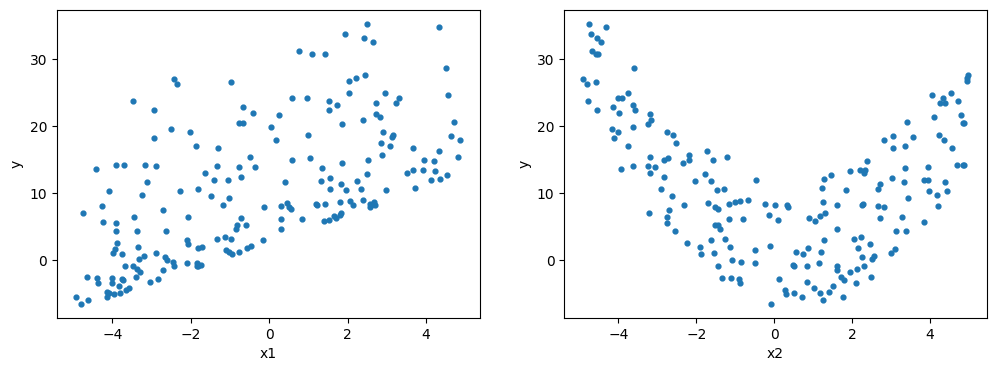

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df["x1"], y, s=12); ax[0].set_xlabel("x1"); ax[0].set_ylabel("y")
ax[1].scatter(df["x2"], y, s=12); ax[1].set_xlabel("x2"); ax[1].set_ylabel("y")
plt.show()

➡ y vs. `x2` looks like a **parabola** → we need a squared term.

## (b) Linear model with polynomial features (degree 2)
`PolynomialFeatures(degree=2)` creates: `1, x1, x2, x1², x1·x2, x2²`.
Then we fit an ordinary linear regression on these new features.

New features: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
Intercept: 3.0
Coefficients: {'x1': np.float64(2.0), 'x2': np.float64(-1.0), 'x1^2': np.float64(0.0), 'x1 x2': np.float64(0.0), 'x2^2': np.float64(1.0)}
R²  : 1.0
MAE : 0.0002


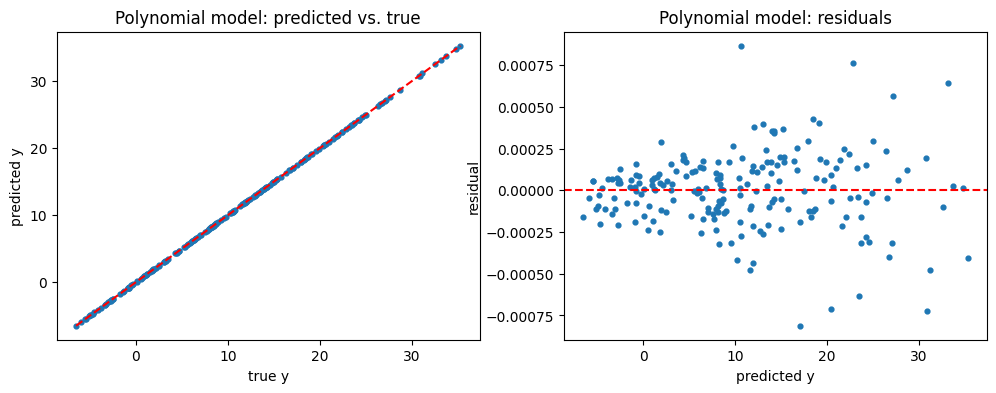

In [4]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
print("New features:", poly.get_feature_names_out(["x1", "x2"]))

lin_poly = LinearRegression().fit(X_poly, y)
y_pred_poly = lin_poly.predict(X_poly)
print("Intercept:", round(lin_poly.intercept_, 3))
print("Coefficients:", dict(zip(poly.get_feature_names_out(["x1", "x2"]), lin_poly.coef_.round(3))))
print("R²  :", round(r2_score(y, y_pred_poly), 5))
print("MAE :", round(mean_absolute_error(y, y_pred_poly), 4))

plot_fit(y, y_pred_poly, "Polynomial model")

## Conclusion
- The polynomial model fits **almost perfectly** (R² ≈ 1.0): points on the diagonal, residuals tiny and without pattern.
- The coefficients reveal the true formula: **y = 3 + 2·x1 − x2 + x2²** (the terms x1² and x1·x2 are 0).
- **Yes, the polynomial model is much better.**

**Lesson:** a linear regression becomes much more powerful when we add suitable generated features (squares, products, logs, …).
Use residual plots to discover that a feature is missing. Caution: too many polynomial terms can lead to **overfitting** – check with test data.